# Workshop 3-3: Decision tree

**Real-life problem:** Spotting forged banknotes, and explaining the decision to someone who isn't technical.

**My twist:** Use `bill_authentication.csv` (four image statistics per note). Plot accuracy against `max_depth` to find where the tree starts overfitting, then print the rules with `sklearn.tree.export_text` and rewrite the top three in plain English.

**Done when:** A chosen depth with evidence, the feature importances, and the plain-English rules. Say which error is worse (accepting a forgery vs rejecting a real note) and how you'd tune for it.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: how a decision tree works (the lecturer's baseline)

A 5-row toy example, then banknote data with a random split. Two small changes so it runs safely on a Mac: the Colab-only `sudo` cell is guarded, and the tree pictures fall back to matplotlib if Graphviz isn't installed. Note the split has no random seed, so Part A's numbers change on every run; Part B fixes that.

In [1]:
# Colab-only setup. The lecturer's original cell ran `!sudo apt-get install graphviz`,
# which hangs on a Mac waiting for a password, so it now only runs on Colab.
# Locally: `pip install pydotplus pydot` (already in requirements.txt) and, optionally for the
# graphviz tree pictures, `brew install graphviz`. Without it the pictures fall back to matplotlib.
import sys
if 'google.colab' in sys.modules:
    get_ipython().system('apt-get -qq install graphviz')
    get_ipython().system('pip install -q pydotplus pydot')

In [2]:
import pydotplus
import pandas as pd
from sklearn import tree
from io import StringIO
import pydot

**Synthetic Case**

In [3]:
data = [ 
(0, 5, 0), 
(1, 6, 0), 
(2, 7, 1), 
(3, 8, 1), 
(4, 9, 1)
]
df = pd.DataFrame(data, index=range(5), columns=['x1','x2','y'])

In [4]:
df

,x1,x2,y
0,0,5,0
1,1,6,0
2,2,7,1
3,3,8,1
4,4,9,1


In [5]:
x_columns = ['x1','x2']
model = tree.DecisionTreeClassifier(criterion='entropy') # Alternative: gini
trained_model = model.fit(df[x_columns], df['y'])

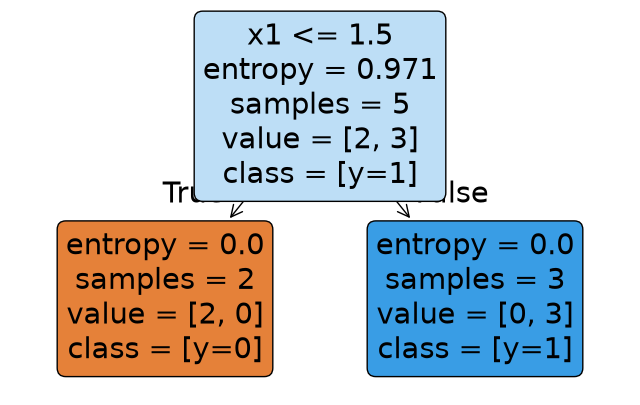

In [6]:
from IPython.display import Image
out_file = tree.export_graphviz(
        trained_model,
        feature_names = x_columns,
        class_names = ['[y=0]', '[y=1]'], # Ascending numerical order
        filled = True,
        rounded = True
)
try:
    graph = pydotplus.graph_from_dot_data(out_file)
    display(Image(graph.create_png()))
except Exception:   # Graphviz's `dot` program is not installed: draw the same tree with matplotlib
    import matplotlib.pyplot as plt
    plt.figure(figsize=(8, 5))
    tree.plot_tree(trained_model, feature_names=x_columns, class_names=['[y=0]', '[y=1]'], filled=True, rounded=True)
    plt.show()

**Real Dataset**

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [8]:
dataset = pd.read_csv("bill_authentication.csv")

In [9]:
dataset.shape

(1372, 5)

In [10]:
dataset.head()

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [11]:
X = dataset.drop('Class', axis=1)
y = dataset['Class']

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)

In [13]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion='entropy')
classifier.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sa

In [14]:
y_pred = classifier.predict(X_test)

In [15]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

[[154   1]
 [  0 120]]


In [16]:
x_columns = ['Variance','Skewness','Curtosis','Entropy']

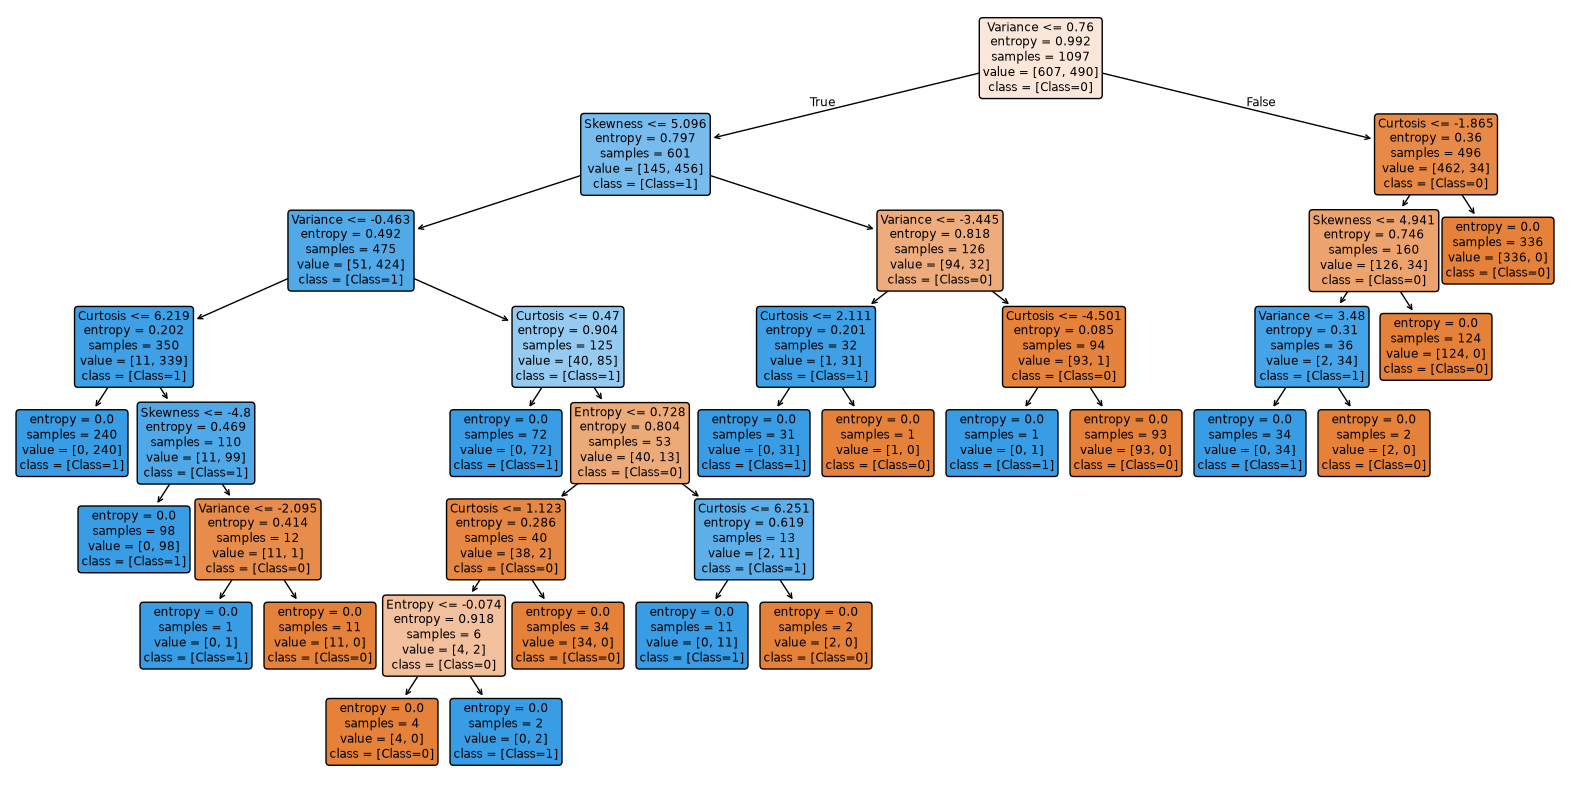

In [17]:
from IPython.display import Image
out_file = tree.export_graphviz(
        classifier,
        feature_names = x_columns,
        class_names = ['[Class=0]', '[Class=1]'], # Ascending numerical order
        filled = True,
        rounded = True
)
try:
    graph = pydotplus.graph_from_dot_data(out_file)
    display(Image(graph.create_png()))
except Exception:   # Graphviz's `dot` program is not installed: draw the same tree with matplotlib
    import matplotlib.pyplot as plt
    plt.figure(figsize=(20, 10))
    tree.plot_tree(classifier, feature_names=x_columns, class_names=['[Class=0]', '[Class=1]'], filled=True, rounded=True)
    plt.show()

---
## Part B: real life: spotting forged banknotes (and explaining why)

**Problem:** a cash desk wants a quick check that flags forged notes. The input is four numbers extracted from a scan of each note (1,372 notes). Two things matter: **how accurate and how simple** the rule can be, and **which mistake is worse**.

**Assumption to check:** the file labels notes `Class` 0 or 1, and the UCI page doesn't say which is which. I treat **1 = forged, 0 = genuine** (the usual reading). If that is wrong, flip `FORGED` below; the numbers stay the same but the words swap.

**Plan:** how deep should the tree be → how often is it wrong, and in which direction → how to make it more cautious → what rules does a human get to read?

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import confusion_matrix

notes = pd.read_csv('bill_authentication.csv')
features = ['Variance', 'Skewness', 'Curtosis', 'Entropy']
X, y = notes[features], notes['Class']
FORGED = 1                                    # assumption: see above

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)    # fixed seed so results repeat

print(f'{len(notes)} notes: {(y == FORGED).sum()} forged, {(y != FORGED).sum()} genuine')
print(f'duplicate rows: {notes.duplicated().sum()} (kept: they are only {notes.duplicated().mean() * 100:.1f}% of the data)')

1372 notes: 610 forged, 762 genuine
duplicate rows: 24 (kept: they are only 1.7% of the data)


### 1. How deep should the tree be?
An unlimited tree can memorise the training notes. To see where extra depth stops helping, compare accuracy on the notes the tree trained on with accuracy on notes it has never seen (5-fold cross-validation), for depths 1 to 12.

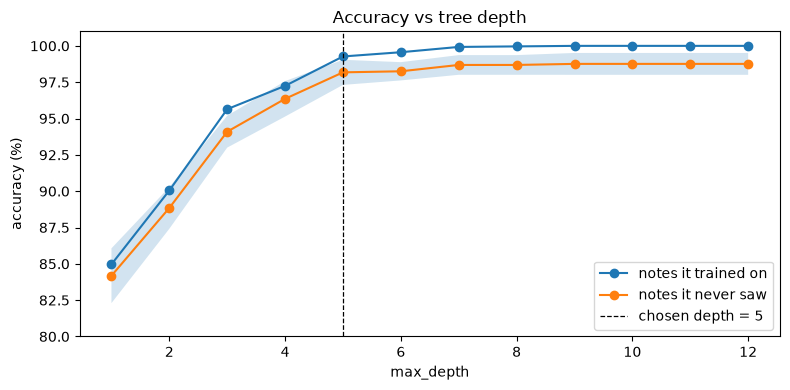

chosen depth 5: unseen accuracy 98.2% with 21 leaves (best possible: 98.8%)


,train accuracy,unseen accuracy,spread,leaves
depth,,,,
1,0.850,0.842,0.019,2
2,0.901,0.888,0.014,4
3,0.956,0.941,0.011,8
4,0.972,0.964,0.012,15
5,0.993,0.982,0.009,21
6,0.996,0.983,0.006,25
7,0.999,0.987,0.007,25
8,1.000,0.987,0.007,25
9,1.000,0.988,0.008,25


In [19]:
rows = []
for depth in range(1, 13):
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=0)
    r = cross_validate(model, X, y, cv=cv, return_train_score=True)
    rows.append({'depth': depth,
                 'train accuracy': r['train_score'].mean(),
                 'unseen accuracy': r['test_score'].mean(),
                 'spread': r['test_score'].std(),
                 'leaves': model.fit(X, y).get_n_leaves()})
depths = pd.DataFrame(rows).set_index('depth')

# simplest tree whose unseen accuracy is within one spread of the best
best = depths['unseen accuracy'].max()
spread_at_best = depths.loc[depths['unseen accuracy'].idxmax(), 'spread']
chosen = int(depths[depths['unseen accuracy'] >= best - spread_at_best].index.min())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths.index, depths['train accuracy'] * 100, 'o-', label='notes it trained on')
ax.plot(depths.index, depths['unseen accuracy'] * 100, 'o-', label='notes it never saw')
ax.fill_between(depths.index, (depths['unseen accuracy'] - depths['spread']) * 100,
                (depths['unseen accuracy'] + depths['spread']) * 100, alpha=0.2)
ax.axvline(chosen, color='k', ls='--', lw=0.9, label=f'chosen depth = {chosen}')
ax.set_xlabel('max_depth'); ax.set_ylabel('accuracy (%)'); ax.set_ylim(80, 101)
ax.set_title('Accuracy vs tree depth'); ax.legend(); plt.tight_layout(); plt.show()

print(f'chosen depth {chosen}: unseen accuracy {depths.loc[chosen, "unseen accuracy"] * 100:.1f}% '
      f'with {depths.loc[chosen, "leaves"]} leaves (best possible: {best * 100:.1f}%)')
depths.round(3)

- **Overfitting is real but mild here.** Training accuracy reaches 100% by depth 8, while accuracy on unseen notes plateaus at about 98.8% from depth 7. The gap is only about 1 point, because the tree runs out of useful splits at 25 leaves.
- **Depth 5 is enough.** It scores about 98.2% on unseen notes, within one spread (0.8 points) of the best, with 21 leaves instead of 25. I choose depth 5 as the simplest tree that is as good as the best.
- **Readability costs accuracy.** Depth 3 has only 8 leaves but drops to about 94%. Section 4 uses it as the explanation, and says so.

### 2. How often is it wrong, and in which direction?
Every note is predicted by a tree that never saw it, using the chosen depth. Which feature does the work?

accuracy 98.2%
forged notes ACCEPTED as genuine:  13 of 610 (2.1%)
genuine notes REJECTED as forged:  12 of 762 (1.6%)


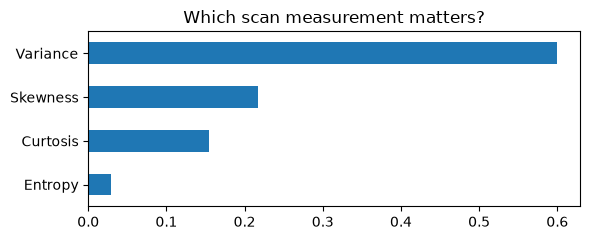

Variance    0.60
Skewness    0.22
Curtosis    0.15
Entropy     0.03
dtype: float64

In [20]:
tree5 = DecisionTreeClassifier(criterion='entropy', max_depth=chosen, random_state=0)
pred = cross_val_predict(tree5, X, y, cv=cv)

tn, fp, fn, tp = confusion_matrix(y == FORGED, pred == FORGED).ravel()
print(f'accuracy {(tn + tp) / len(y) * 100:.1f}%')
print(f'forged notes ACCEPTED as genuine:  {fn} of {fn + tp} ({fn / (fn + tp) * 100:.1f}%)')
print(f'genuine notes REJECTED as forged:  {fp} of {fp + tn} ({fp / (fp + tn) * 100:.1f}%)')

importance = pd.Series(tree5.fit(X, y).feature_importances_, index=features).sort_values()
importance.plot(kind='barh', figsize=(6, 2.5), title='Which scan measurement matters?')
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(2)

- **Accepting a forgery is the worse mistake.** It loses the note's face value and may be illegal, while rejecting a genuine note costs a customer a moment of friction and a second check. So we should accept some extra false alarms to let fewer forgeries through. (That is a judgement; the cash desk's own costs would settle it.)
- **At depth 5 about 2% of forged notes get through** (13 of 610) and about 1.6% of genuine notes are rejected (12 of 762).
- **Variance does most of the work** (about 60% of the tree's decisions), then Skewness (22%) and Curtosis (15%). **Entropy is nearly useless** (3%), so the scanner could skip it.

### 3. Making it more cautious
Give forged notes a bigger weight (`class_weight`) so the tree works harder not to miss them. Because a tree on 1,372 notes is unstable, each setting is repeated over 10 different cross-validation splits and shown with its spread.

In [21]:
rows = []
for weight in (1, 3, 10, 30):
    accepted, rejected = [], []
    for seed in range(10):
        model = DecisionTreeClassifier(criterion='entropy', max_depth=chosen, random_state=0,
                                       class_weight={FORGED: weight, 1 - FORGED: 1})
        p = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=seed))
        tn, fp, fn, tp = confusion_matrix(y == FORGED, p == FORGED).ravel()
        accepted.append(fn); rejected.append(fp)
    rows.append({'weight on forged notes': weight,
                 'forged accepted (of 610)': f'{np.mean(accepted):.1f} ± {np.std(accepted):.1f}',
                 'genuine rejected (of 762)': f'{np.mean(rejected):.1f} ± {np.std(rejected):.1f}'})
pd.DataFrame(rows).set_index('weight on forged notes')

,forged accepted (of 610),genuine rejected (of 762)
weight on forged notes,,
1,11.3 ± 3.8,14.0 ± 4.0
3,9.1 ± 2.5,15.1 ± 3.4
10,7.9 ± 1.3,21.4 ± 6.0
30,4.5 ± 1.4,31.3 ± 4.3


- **The dial works, but it is not free.** Weight 1 vs 3 are within the spread, so I can't tell them apart. At weight 10, forged notes let through fall from about 11 to about 8, while genuine notes rejected rise from 14 to 21. At weight 30 only about 4 or 5 forgeries get through, but about 31 genuine notes (4%) are rejected.
- **How to choose:** going from weight 1 to 10 swaps about 3.4 forgeries for about 7.4 extra rejections, so it pays off only if one forged note costs more than roughly 2 rejected genuine ones. For a cash desk that is very likely (a forgery loses the note's face value; a rejection costs a customer a few seconds), so I would use **weight 10**. That is an assumption to confirm with real costs.

### 4. Rules a human can read
Depth 5 is too big to read out loud (21 leaves). For an explanation I use a **depth-3 "explainer" tree** (8 leaves, about 94% accurate on unseen notes). Each line shows `[genuine, forged]` counts in that leaf.

explainer tree: 8 leaves, 94.1% accurate on unseen notes

|--- Variance <= 0.32
|   |--- Skewness <= 5.87
|   |   |--- Curtosis <= 6.22
|   |   |   |--- weights: [2.00, 363.00] class: 1
|   |   |--- Curtosis >  6.22
|   |   |   |--- weights: [25.00, 131.00] class: 1
|   |--- Skewness >  5.87
|   |   |--- Variance <= -3.44
|   |   |   |--- weights: [1.00, 39.00] class: 1
|   |   |--- Variance >  -3.44
|   |   |   |--- weights: [96.00, 0.00] class: 0
|--- Variance >  0.32
|   |--- Variance <= 1.79
|   |   |--- Curtosis <= -2.27
|   |   |   |--- weights: [3.00, 54.00] class: 1
|   |   |--- Curtosis >  -2.27
|   |   |   |--- weights: [158.00, 18.00] class: 0
|   |--- Variance >  1.79
|   |   |--- Curtosis <= -4.80
|   |   |   |--- weights: [2.00, 3.00] class: 1
|   |   |--- Curtosis >  -4.80
|   |   |   |--- weights: [475.00, 2.00] class: 0



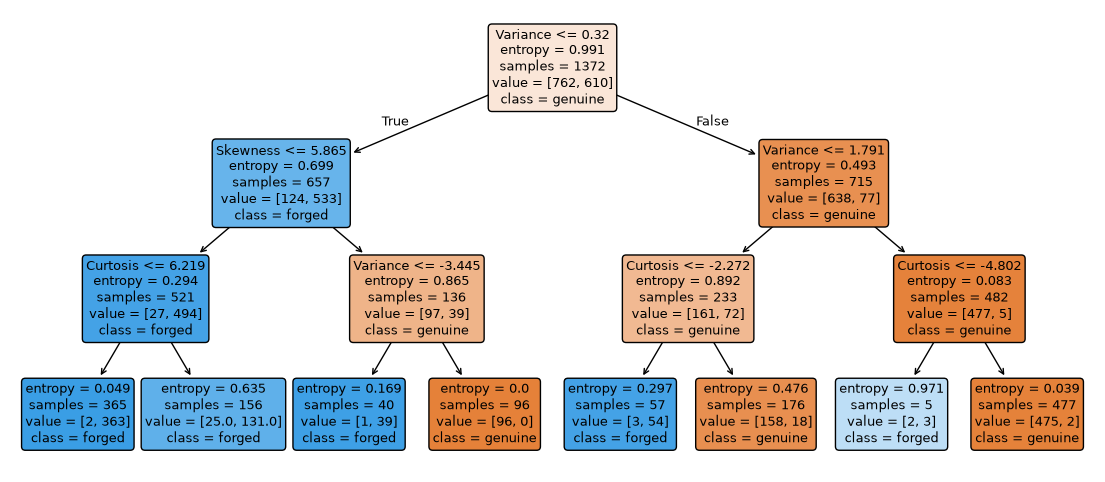

In [22]:
explainer = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=0).fit(X, y)
acc3 = cross_val_score(DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=0), X, y, cv=cv).mean()
print(f'explainer tree: {explainer.get_n_leaves()} leaves, {acc3 * 100:.1f}% accurate on unseen notes\n')
print(export_text(explainer, feature_names=features, show_weights=True))

plt.figure(figsize=(14, 6))
plot_tree(explainer, feature_names=features, class_names=['genuine', 'forged'] if FORGED == 1 else ['forged', 'genuine'],
          filled=True, rounded=True, fontsize=9)
plt.show()

**Plain English: the top three rules** (the three that cover the most notes: 1,174 of 1,372, or 86%). *Variance is a number from the scan's analysis; think of it as how much fine detail varies across the note.*

1. **High variance means genuine.** If variance is above 1.8 (and curtosis isn't extremely low, below −4.8), the note is genuine. This covers 477 notes and is right 99.6% of the time (475 genuine, 2 forged).
2. **Low variance means forged.** If variance is 0.3 or below and skewness is under 5.9, the note is forged. This covers 521 notes and is right 95% of the time (494 forged, 27 genuine).
3. **Middling variance, mostly genuine.** If variance is between 0.3 and 1.8 and curtosis is above −2.3, the note is genuine. This covers 176 notes and is right 90% of the time (158 genuine, 18 forged), the least certain of the three.

The other five leaves handle the remaining 14% of notes, the awkward in-between cases.

### Recommendation
Use a **depth-5 tree with a weight of about 10 on forged notes**: about 98% accurate overall, with roughly 1 forged note in 75 getting through and 1 genuine note in 36 rejected (at weight 10, from the table above). **Explain it with the depth-3 tree and the three rules above**, and be upfront that the simple version is only about 94% accurate. In practice, send "in-between" notes (the low-confidence leaves) to a person for a second check rather than deciding automatically.

**Caveats:** the file doesn't say which label is forged (I assumed 1); there are only 610 forged examples and 24 duplicate rows; the four numbers come from a particular scanner pipeline, so a different scanner would need re-testing; and forgers adapt, so the tree needs re-checking over time.